In [1]:
%fdp_login

Logged in to d3d. Token valid for 24.0 h; groups ['DIII-D']
  Data access is ready.


True

I'll start by planning this task and consulting the relevant skill for fetching DIII-D EFIT signals.



The skill is not in the Learnings list, so no Learnings.md to read. Now writing the fetch script for `\ipmhd` from efit01 on shot 165340.





Running the fetch under the `fdp run` wrapper, which the skill requires for DIII-D data access.



Fetch succeeded — 311 samples, 50 Hz cadence. Let me verify what `\ipmhd` physically represents from the signal catalog rather than inferring it from the tag name.



Now looking up what `\ipmhd` actually measures and the shot's stored current summary, so the meaning and units come from the catalog rather than the tag name.



/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/fdp-demo/_d3d_pelican_sage_/lookup_ipmhd_meaning.py:1: SyntaxWarning: invalid escape sequence '\i'
  """Catalog lookup: what does \ipmhd mean, and shot 165340's stored current scalars."""


Catalog confirms the meaning and units. Now verifying the output files landed correctly and the CSV matches the reported numbers.



CSV has 311 data rows plus header, matching the reported sample count. Let me independently verify min/max from the saved file.



All numbers verified independently from the saved CSV. Updating the plan and reporting.



## `\ipmhd` from efit01, DIII-D shot 165340

The signal fetched cleanly: 311 samples spanning 100–6360 ms at a 20 ms cadence (50 Hz), with no NaNs and no fetch errors.

**Samples** : 311
**Time base** : 100.0 to 6360.0 ms, uniform 20.0 ms spacing (50.0 Hz)
**Minimum** : 2.920250e+05 A (0.2920 MA), at t = 6360.0 ms — the final sample, as the current ramps down
**Maximum** : 1.187812e+06 A (1.1878 MA), at t = 3060.0 ms
**Mean over the trace** : 1.0767 MA
**Units** : A (amperes), as reported by the signal's own units field


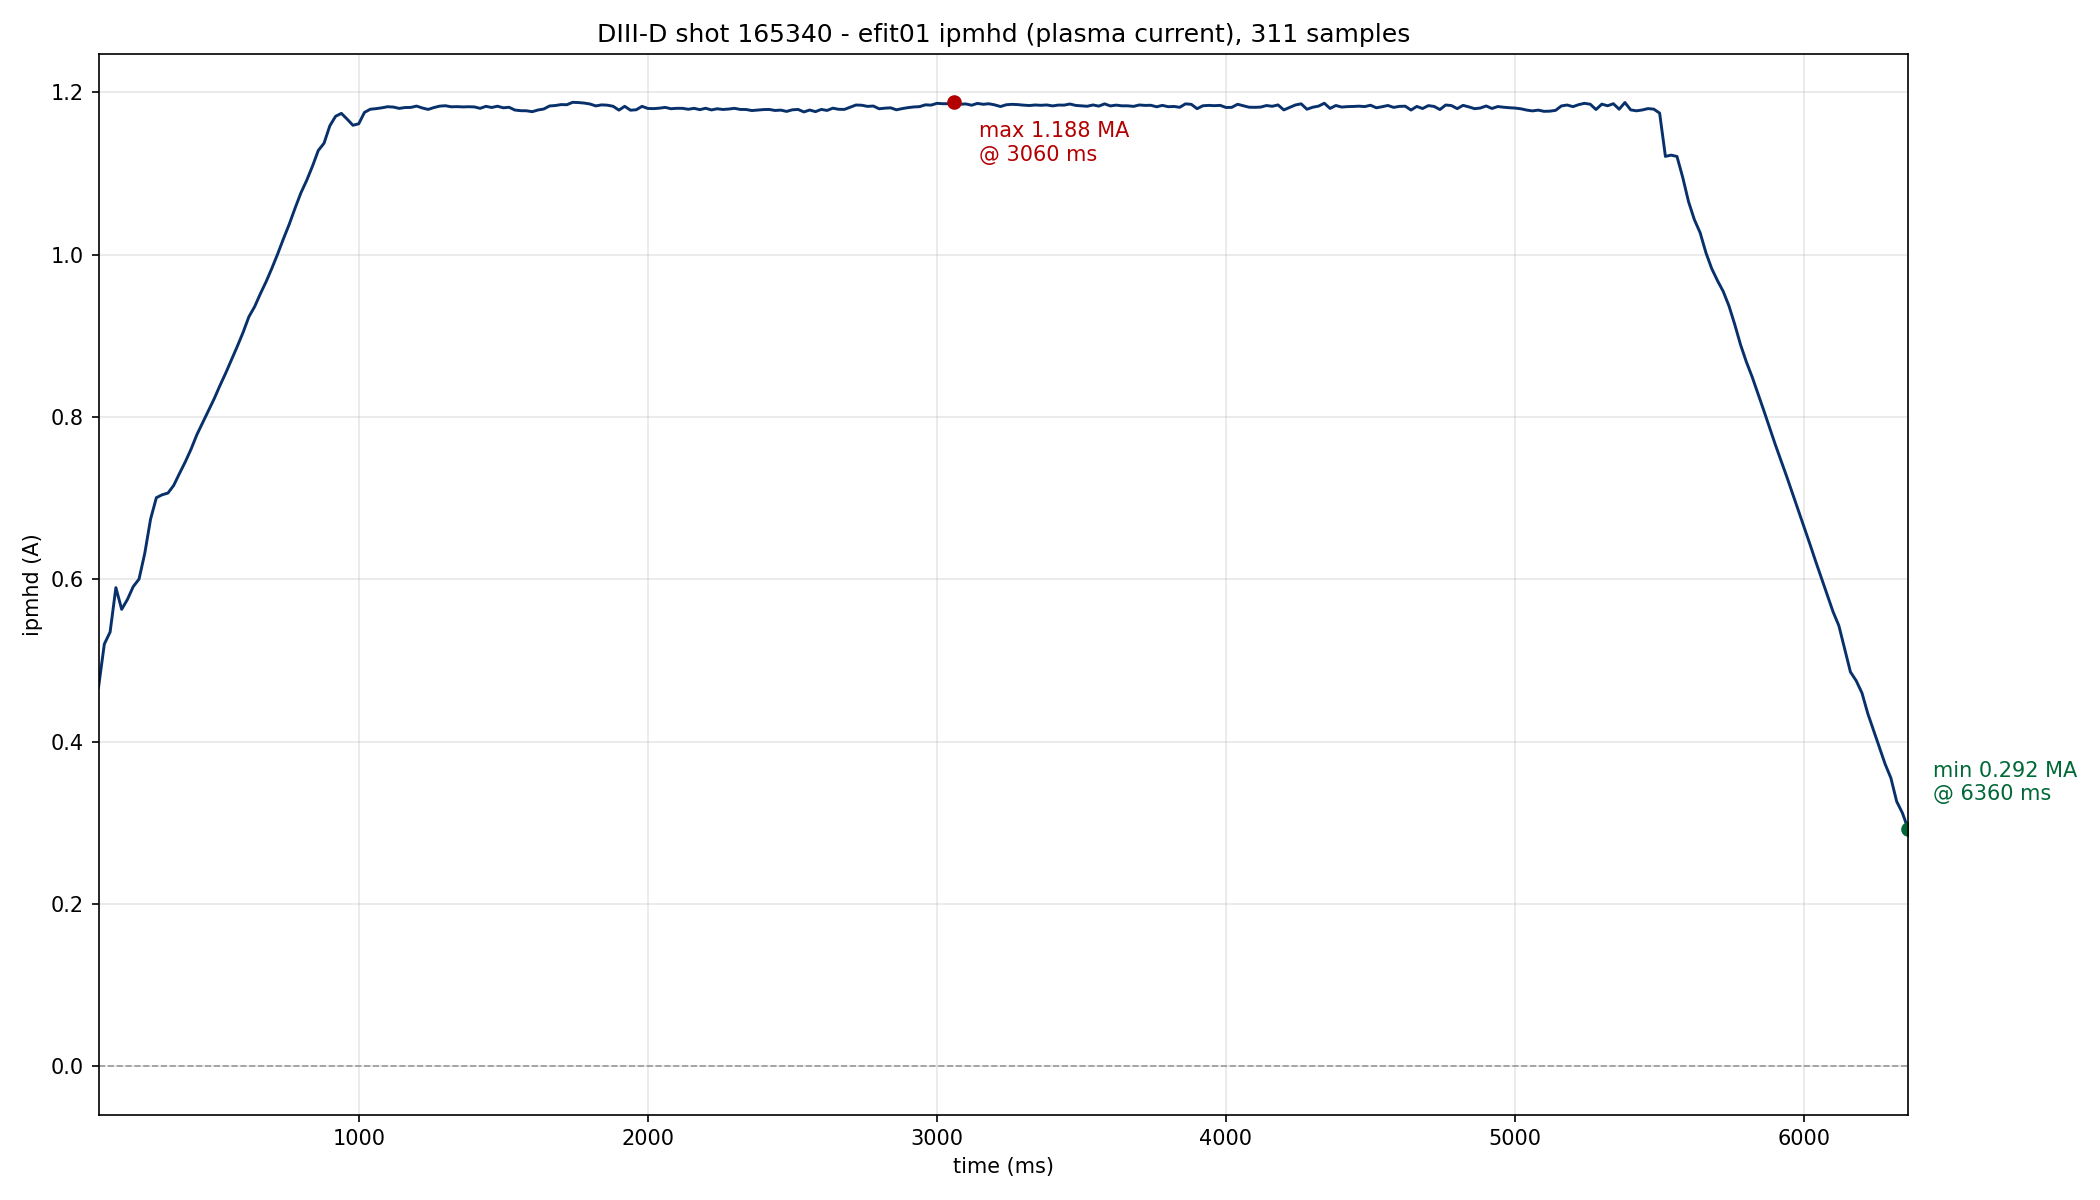

### What the signal is

The catalog describes `IPMHD` as the **fitted plasma current** , in amperes — the current that the EFIT equilibrium reconstruction fits to the magnetic measurements, not a raw digitizer trace. One caveat worth stating plainly: that description is attached to the `EFIT` tree entry. The `EFIT01` entry for the same name carries no description and no units in the catalog, so the "fitted plasma current / A" wording is inherited from the sibling `EFIT` record and is unconfirmed for `EFIT01` specifically. The units field returned with the fetched data itself is `A`, which is consistent.

### Cross-check against the shot summary

The shot's stored summary values describe the same quantity through a different pipeline, and they agree closely:

| Quantity | Stored summary | This `\ipmhd` trace |
|---|---|---|
| Peak plasma current | 1.19457 MA (at t = 1.764 s) | 1.18781 MA (at t = 3.060 s) |
| Flattop current | 1.18132 MA | — |
| Pulse length | 6.551 s | trace ends 6.360 s |

The peak differs by about 0.6%, and the times of peak differ because the stored value is a separately computed representative scalar while the trace's own maximum is an empirical point on the sampled grid. These are two valid measurements of the same physical quantity, not one correct and one wrong. The trace's 6.36 s endpoint sits just inside the 6.55 s pulse length, consistent with EFIT's reconstruction window ending before the current fully decays.

### Data files

- `ipmhd_efit01_165340.csv` — the full trace, 311 rows, columns `time_ms` and `ipmhd_A`, so every number above can be re-checked against the raw values.
- `ipmhd_efit01_165340.png` — the plot shown above.
- `fetch_ipmhd_165340.py` — the fetch/plot script.
- `lookup_ipmhd_meaning.py` — the catalog lookup used for the signal's meaning and units.

In [2]:
%%ask
Fetch \ipmhd from efit01 for shot 165340 and plot it versus time, and
report the number of samples and the min/max with units.

In [5]:
%%ask
How many tungsten samples do you have?

Reading the rest of the skill and the helper module to see how sample materials are recorded.



Reading the helper module to see what fields `samples()` returns and how material is recorded.



The `samples()` helper returns a `material` column, so I'll query the full sample catalogue and count by material.



All 9 samples carry material "W" — the chemical symbol for tungsten. Let me confirm the ontology maps "W" to tungsten and check the delivery notes for context.



**9 tungsten samples** — the entire materials catalogue in the FEDER lakehouse is tungsten.

The `materials.samples` table holds 9 samples, all with `material = "W"`, and the FEDER ontology confirms `W → tungsten` (exact match, `https://w3id.org/feder/ontology/v4/common-materials#Tungsten`). They come from a single delivery (`2026-09-04_amy`, provider "Amy", received 2026-09-04) — a tungsten erosion/retention study with DIII-D exposures.

**The 9 samples** :

| Sample | Material | Notes |
|---|---|---|
| W-pristine | W | never entered DIII-D (reference) |
| W-He600 | W | He pre-exposed, 600 K |
| W-He800 | W | He pre-exposed, 800 K |
| W-DH | W | DIII-D, H-mode |
| W-DL | W | DIII-D, L-mode |
| W-He600-DH | W | He 600 K + DIII-D H-mode |
| W-He800-DH | W | He 800 K + DIII-D H-mode |
| W-He600-DL | W | He 600 K + DIII-D L-mode |
| W-He800-DL | W | He 800 K + DIII-D L-mode |

**Data file** : `tungsten_samples.json` — the full sample list with names, materials, and delivery IDs.

In [3]:
%%ask
For the following question:
"Under what conditions do these facilities (D3D, MAST) have sustained good 
energy confinement at high plasma density?",

How to answer this question? Please make a plan.

I'll plan this out, but first I need to ground the plan in what these skills actually hold — a plan that promises confinement and density data that doesn't exist would be worthless.



Reading the DIII-D relational database skill to see which per-shot scalars it exposes — density and confinement in particular.



Now the MAST side and the DIII-D signal-fetching skill, to see what confinement and density quantities each device actually exposes.



Now the DIII-D fetch skill and the literature skill, to see whether confinement time and density-limit quantities are reachable and how published findings are retrieved.



I'll plan this without touching any data. First, tracking the steps.



...

Running the probe to identify which density signal is usable and how well confinement signals cover shots.



The picture is now clear enough to plan concretely. One last check — whether the shot-summary columns needed for a confinement scaling are jointly populated, since that decides whether a broad survey is viable.



Running the survey-viability query to see how many shots carry all the inputs jointly.





I now have everything needed to write a grounded plan. Let me record the findings and finalize.



## How to answer this question: a plan

I probed the actual data before planning, because the honest answer depends on what these two devices' archives really carry. The short version: **the question is answerable as a data-driven survey, but not in the form it is phrased.** "Sustained good confinement at high density" is a claim about a *regime*, and neither archive has a regime label. What both have is the raw ingredients to *construct* the regime criterion and then measure where it holds.

### What I verified is available

**DIII-D — strong coverage.** The shot summary data holds 90,644 plasma shots spanning shots 55,102–208,740. Jointly populated inputs:

| Input set | Shots |
|---|---|
| Greenwald fraction from average density | 65,439 |
| Greenwald fraction from peak density | 60,657 |
| Confinement inputs (core, ohmic only) | 64,698 |
| Confinement inputs + beam power | 57,349 |
| Confinement inputs + beam + radiated power | 21,122 |
| Flattop duration > 2 s | 58,440 |

That is a genuine survey population — tens of thousands of shots with density, current, minor radius, field, elongation, stored energy and heating power all present.

**MAST — thin but real.** The public Zarr store lists 701 shots (11766–12795). Per shot it carries `summary.line_average.n_e.value`, `summary.global_quantities.ip`, NBI and ohmic power, and from `equilibrium` it carries `energy_mhd`, `q_95`, `beta_tor`, `minor_radius`, `b0`, `volume`. That is enough for both a Greenwald fraction and a confinement time.

### The four problems the plan must solve

These are the reasons a naive "just plot it" answer would be wrong, and each one changes a step below.

**1. `\taue` is not trustworthy as stored.** On shot 194000 it returns **19 samples over 100–800 ms** with a minimum of **−0.16 s** . On 165920 it is absent entirely. A negative confinement time is unphysical, and 19 samples is not a discharge. Confinement must be **derived** as $\tau_E = W_{\rm MHD}/(P_{\rm heat} - dW/dt)$ from stored energy and power, not read from the stored column. The stored `\taue` is usable only as a cross-check on shots where it is sane.

**2. `\pbeam` and `\prad` fail on the efit01 tree.** Both returned `NONE` on all four shots I tried. Heating power must come from the shot-summary scalars (`pbeam`, `poh`, `prad`), which are populated on 58,821 / 64,990 / 29,679 rows respectively — not from the equilibrium tree.

**3. MAST's `energy_mhd` and `beta_tor` contain unphysical negatives.** Shot 12795 gives `energy_mhd` down to −46,691 J and `beta_tor` down to −5.34; shot 12302 gives `beta_tor` down to −13.65. These are reconstruction failures, not measurements. Any MAST confinement number must be computed only on samples where the equilibrium converged, and the fraction discarded must be reported. MAST also has **no `core_profiles` and no `transport` IDS** — so no density or temperature *profiles*, only line-averaged density. A MAST density-limit statement therefore rests on a line average, which is a weaker basis than DIII-D's.

**4. The literature cannot answer it.** The only literature scope in this environment is the tungsten materials delivery, holding 4 papers: Wagner 2007 (H-mode), Ziegler 2010 (SRIM), Guillemaut 2015 (JET ELM ion energy), Baldwin 2017 (W isotope transport). None addresses density limits on D3D or MAST. So the published-context route is closed, and the answer must come from the data. I will not dress up a general-knowledge recollection of the Greenwald limit as a finding from these archives.

### The plan

**Step 1 — Define the regime criterion explicitly, before measuring.**
Two thresholds, both stated as numbers in the answer:
- *High density*: Greenwald fraction $f_G = \bar{n}_e / n_G$ with $n_G = I_p/(\pi a^2)$ in $10^{20}\,\mathrm{m^{-3}}$, $\mathrm{MA}$, $\mathrm{m}$. Report the distribution of $f_G$ and pick the high-density band from it (likely $f_G > 0.7$), rather than asserting a threshold from memory.
- *Good confinement*: $H_{98y2} = \tau_E/\tau_{E,98y2}$ above a stated value (likely $H_{98y2} \geq 1.0$), with $\tau_E$ derived as in problem 1.
- *Sustained*: the criterion must hold for a stated minimum duration within the flattop, not at a single instant. This is what separates "reached" from "sustained", and it is the part most likely to be skipped.

**Step 2 — DIII-D survey.** Compute $f_G$ and $H_{98y2}$ per shot from the summary scalars across the ~57k shots with beam power, then count and characterise the shots in the high-density/good-confinement corner. Filter out the unphysical rows first — note `density_avg` has a minimum of **−3.09e21 m⁻³** , so negative densities exist in the summary data and must be excluded rather than averaged in.

**Step 3 — DIII-D time-resolved confirmation.** For the handful of shots that satisfy the criterion, fetch `\densv2`, `\wmhd`, `\ipmhd`, `\aminor`, `\q95`, `\betan` from efit01 (all verified working, 311 samples over the full discharge on 165340) and confirm the regime is held over a sustained window rather than being a fluke of a single summary scalar. This is where "sustained" gets its evidence.

**Step 4 — MAST survey.** Same quantities from the Zarr store across the 701 available shots, restricted to converged equilibrium samples, with the discarded fraction reported. Expect a much smaller usable sample and say so.

**Step 5 — Compare the conditions, which is the actual question.** The question asks *under what conditions*, so the deliverable is the conditions, not the counts: shape (elongation, triangularity), $q_{95}$, heating mix (NBI vs ohmic), field, current, and whether the high-$f_G$ good-$H$ shots cluster at particular $q_{95}$ or shaping. Plot $H_{98y2}$ against $f_G$ with the regime box drawn, and a second panel of the condition that separates the successes.

**Step 6 — State the limits.** DIII-D's summary scalars are one number per shot, so a survey built on them cannot distinguish a sustained regime from a transient excursion — Step 3 exists to cover that gap for a few shots, not all. MAST's line-average-only density and its negative-energy samples bound how strongly its result can be stated. And the answer describes these two archives, not the devices' full published record.

### What I would not do

I would not answer this from general knowledge about density limits and tokamak confinement. The question names two specific devices, and the interesting answer is what *these* archives show — including the possibility that the high-density good-confinement corner is sparsely populated or that the two devices differ. If the data turns out not to support a clean statement, that is the finding, and it is worth more than a fluent summary of textbook physics.

Shall I proceed with this plan? If you would prefer a narrower scope — DIII-D only, or a specific shot range or campaign rather than the full 90k-shot archive — say so and I will adjust before running the survey.